In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("retail_store_sales_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10531, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [5]:
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Data types:
Transaction ID              object
Customer ID                 object
Category                    object
Item                        object
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
Discount Applied            object
dtype: object

Missing values:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64


In [6]:
monthly_sales = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

print(monthly_sales)

Transaction Date
2022-01    49141.5
2022-02    37480.0
2022-03    36678.0
2022-04    35510.5
2022-05    33906.5
2022-06    38513.0
2022-07    38708.5
2022-08    36486.0
2022-09    41120.0
2022-10    34257.0
2022-11    35704.5
2022-12    34646.0
2023-01    42467.5
2023-02    33009.5
2023-03    34237.5
2023-04    33468.5
2023-05    34493.5
2023-06    37557.0
2023-07    38043.0
2023-08    34423.0
2023-09    36552.5
2023-10    33816.0
2023-11    32852.5
2023-12    37484.5
2024-01    41262.5
2024-02    32950.5
2024-03    37872.0
2024-04    42661.5
2024-05    37929.5
2024-06    38915.5
2024-07    35970.0
2024-08    37522.0
2024-09    38655.0
2024-10    38495.5
2024-11    36557.0
2024-12    42109.0
2025-01    23783.0
Name: Total Spent, dtype: float64


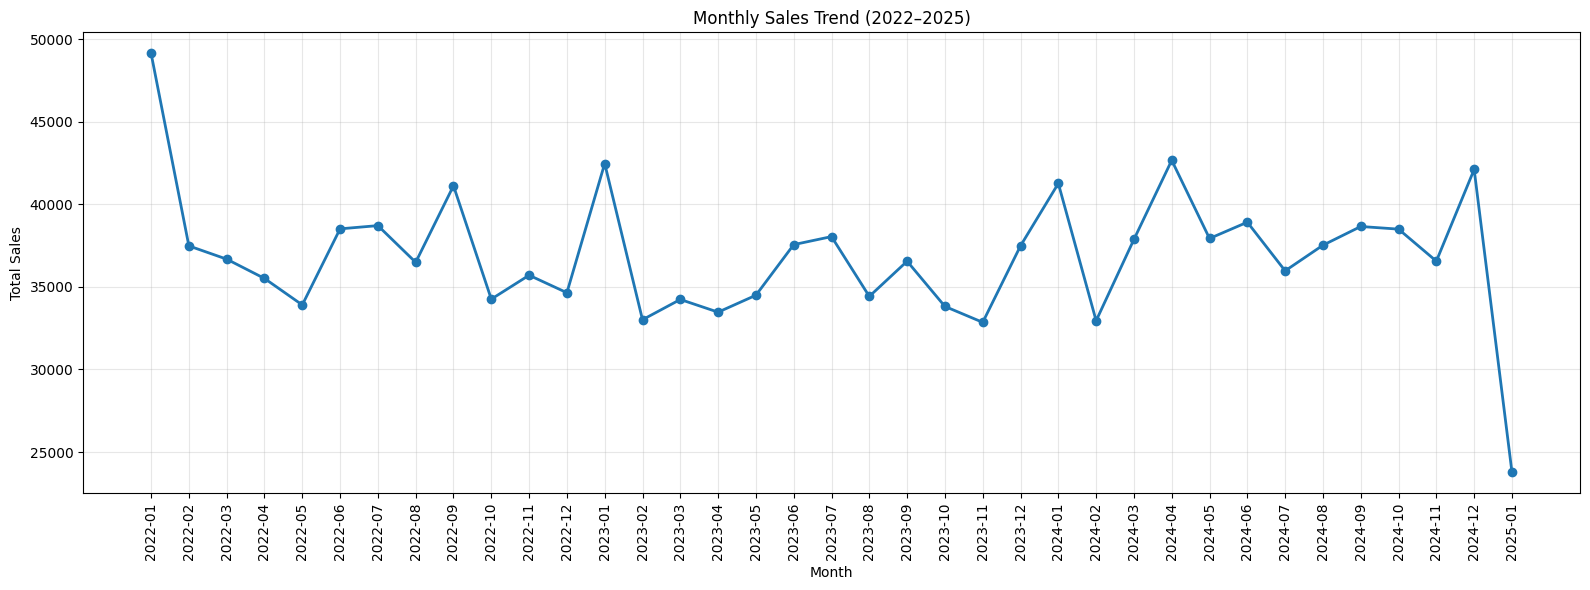

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

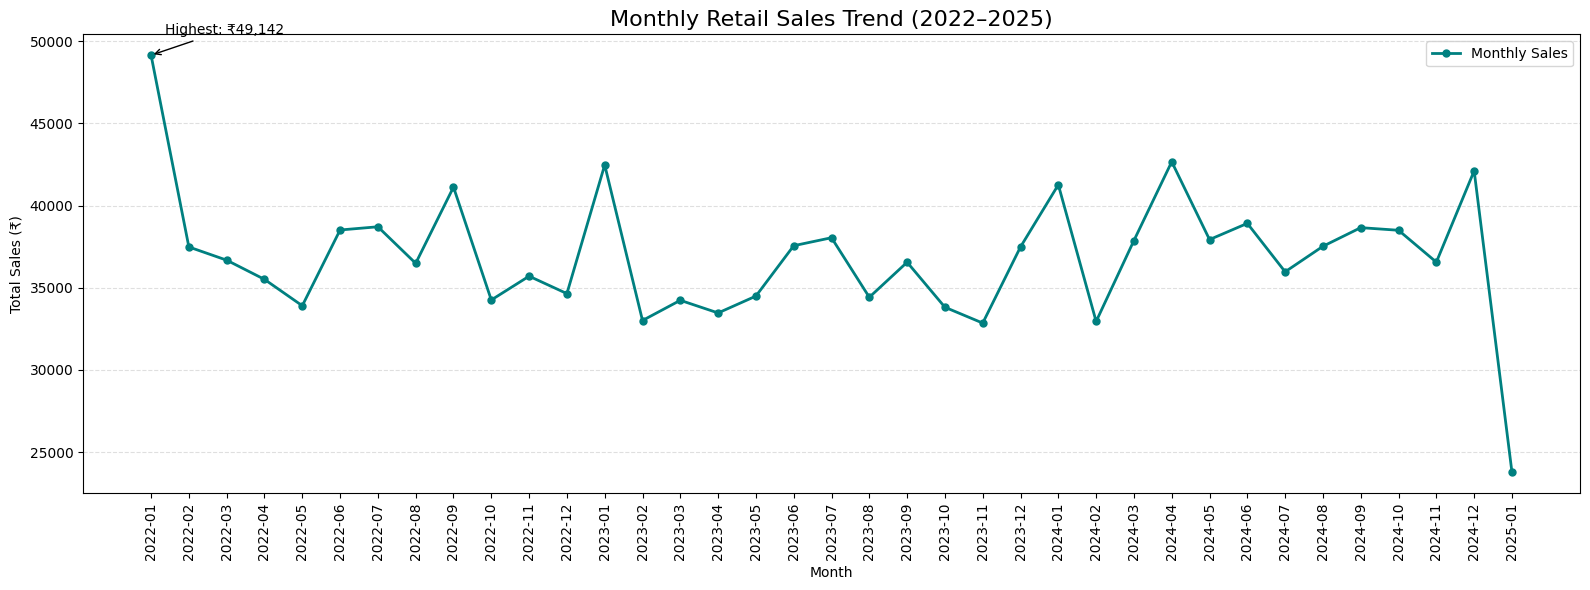

In [8]:
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="teal",
    marker="o",
    markersize=5,
    linewidth=2,
    label="Monthly Sales"
)

# Highlight highest sales month
peak_month = monthly_sales.idxmax()
peak_sales = monthly_sales.max()

plt.annotate(
    f"Highest: ₹{peak_sales:,.0f}",
    xy=(peak_month, peak_sales),
    xytext=(10, 15),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.title("Monthly Retail Sales Trend (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
yearly_sales = df.groupby(
    df["Transaction Date"].dt.year
)["Total Spent"].sum()

print("Year-wise Sales:")
print(yearly_sales)

Year-wise Sales:
Transaction Date
2022    452151.5
2023    428405.0
2024    460900.0
2025     23783.0
Name: Total Spent, dtype: float64


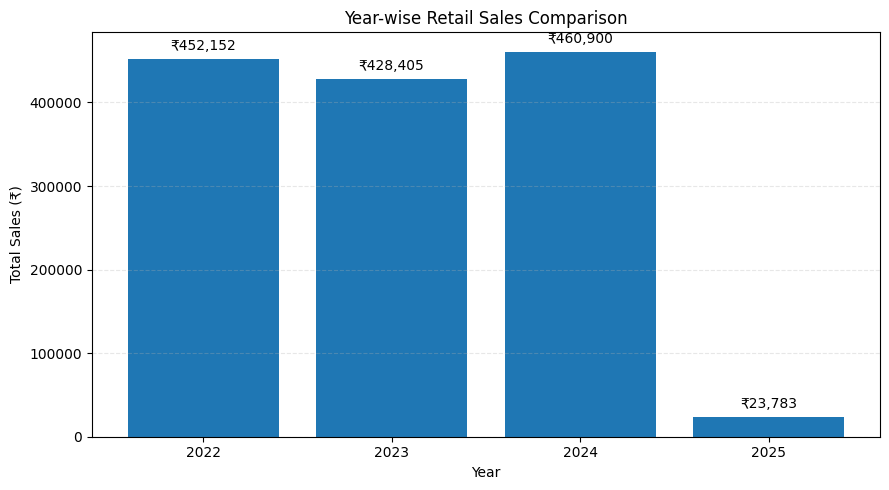

In [10]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    yearly_sales.index.astype(str),
    yearly_sales.values
)

plt.title("Year-wise Retail Sales Comparison")
plt.xlabel("Year")
plt.ylabel("Total Sales (₹)")

plt.bar_label(
    bars,
    labels=[f"₹{value:,.0f}" for value in yearly_sales.values],
    padding=4
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
category_sales = (
    df.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print("Category-wise Sales:")
print(category_sales)

Category-wise Sales:
Category
Butchers                              186638.5
Electric household essentials         178218.0
Food                                  173674.5
Beverages                             171901.0
Furniture                             171427.0
Computers and electric accessories    165676.5
Patisserie                            159007.0
Milk Products                         158697.0
Name: Total Spent, dtype: float64


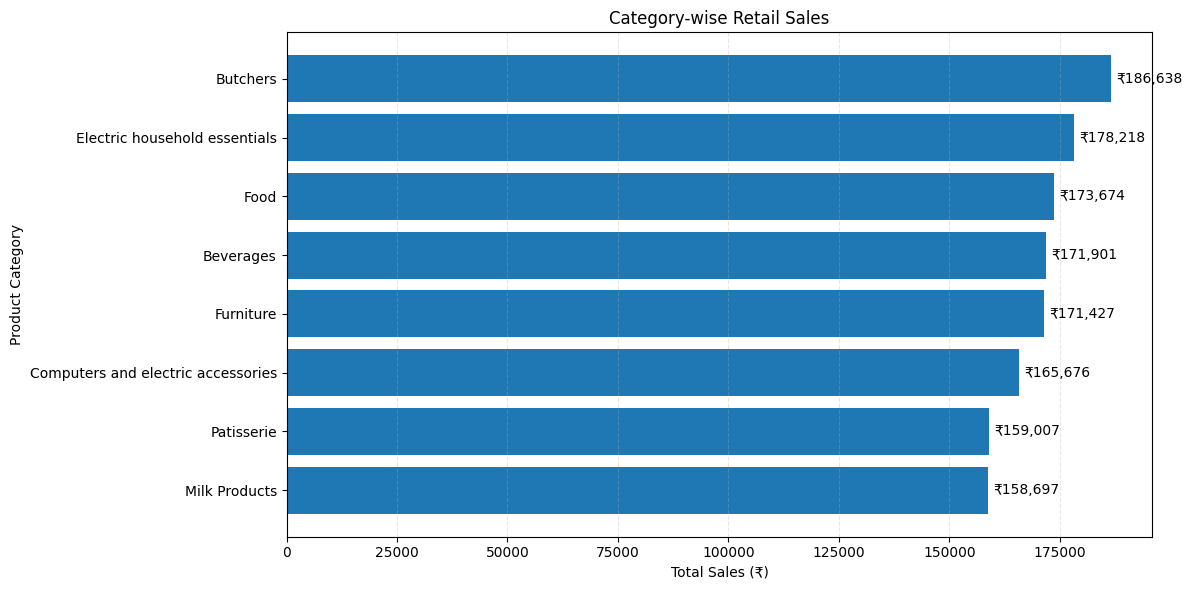

In [12]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    category_sales.index,
    category_sales.values
)

plt.title("Category-wise Retail Sales")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Product Category")

plt.bar_label(
    bars,
    labels=[f"₹{value:,.0f}" for value in category_sales.values],
    padding=4
)

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
payment_sales = (
    df.groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print("Payment Method-wise Sales:")
print(payment_sales)

Payment Method-wise Sales:
Payment Method
Cash              471034.0
Digital Wallet    448821.0
Credit Card       445384.5
Name: Total Spent, dtype: float64


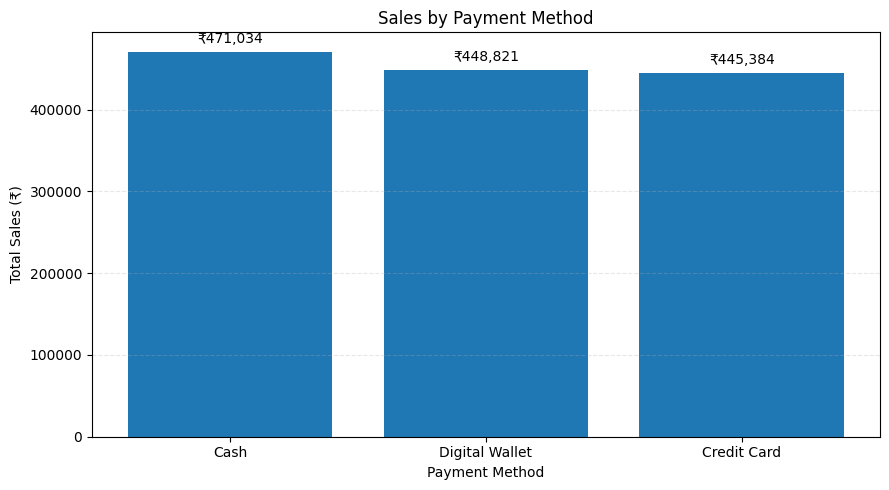

In [14]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    payment_sales.index,
    payment_sales.values
)

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales (₹)")

plt.bar_label(
    bars,
    labels=[f"₹{value:,.0f}" for value in payment_sales.values],
    padding=4
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
location_sales = (
    df.groupby("Location")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print("Location-wise Sales:")
print(location_sales)

Location-wise Sales:
Location
Online      694769.5
In-store    670470.0
Name: Total Spent, dtype: float64


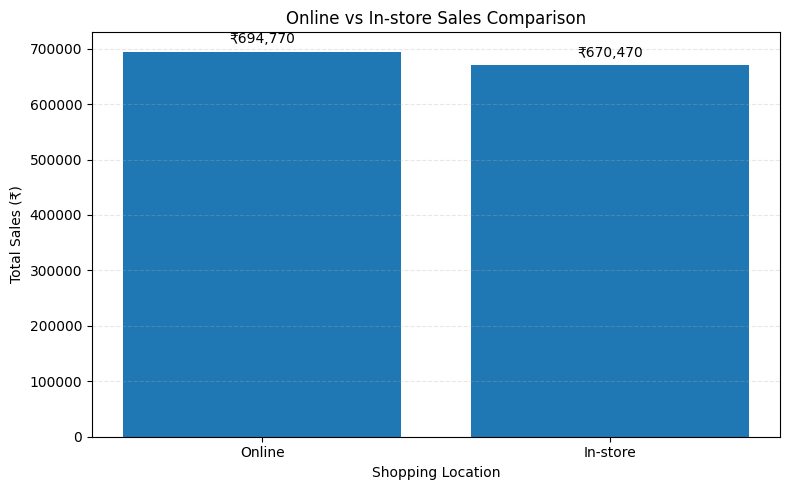

In [16]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    location_sales.index,
    location_sales.values
)

plt.title("Online vs In-store Sales Comparison")
plt.xlabel("Shopping Location")
plt.ylabel("Total Sales (₹)")

plt.bar_label(
    bars,
    labels=[f"₹{value:,.0f}" for value in location_sales.values],
    padding=4
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

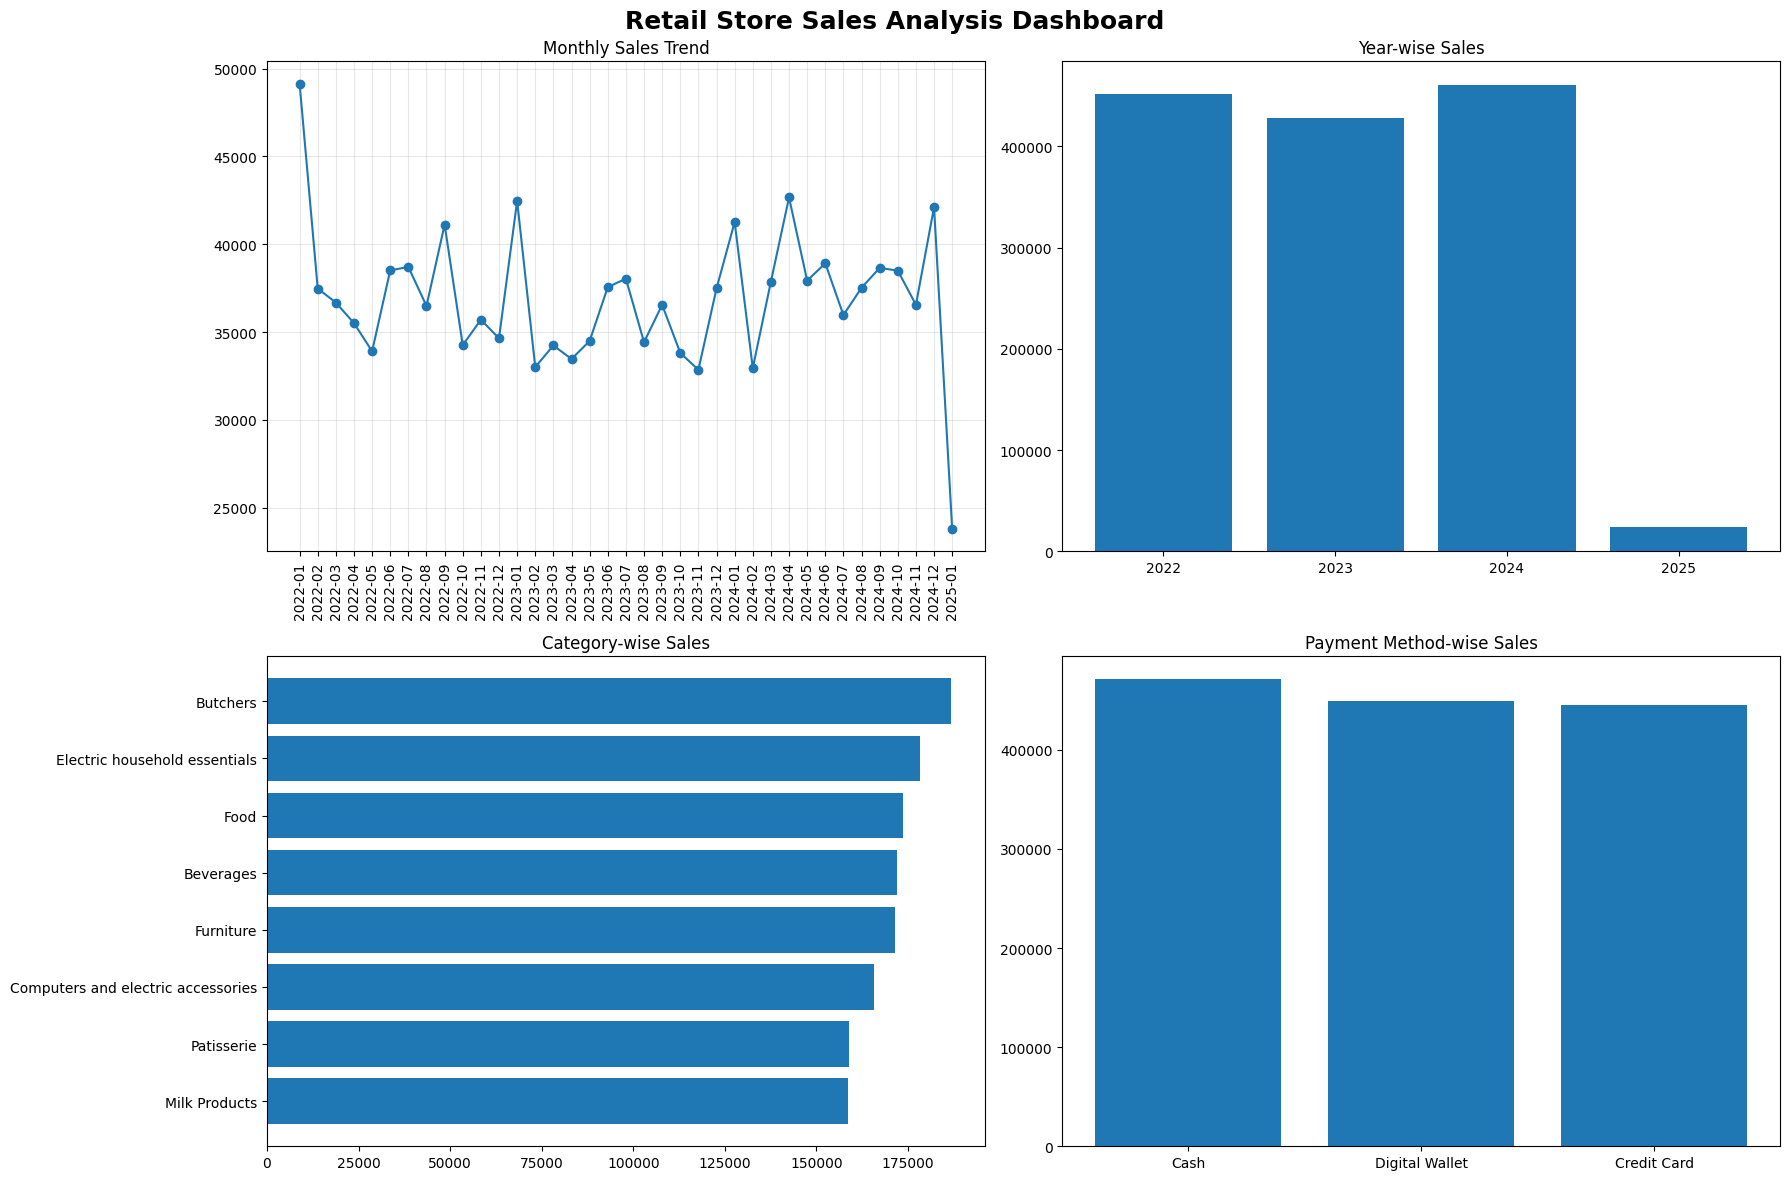

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Monthly Sales Trend
axes[0, 0].plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)
axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].tick_params(axis="x", rotation=90)
axes[0, 0].grid(alpha=0.3)

# 2. Year-wise Sales
axes[0, 1].bar(
    yearly_sales.index.astype(str),
    yearly_sales.values
)
axes[0, 1].set_title("Year-wise Sales")

# 3. Category-wise Sales
axes[1, 0].barh(
    category_sales.index,
    category_sales.values
)
axes[1, 0].set_title("Category-wise Sales")
axes[1, 0].invert_yaxis()

# 4. Payment Method-wise Sales
axes[1, 1].bar(
    payment_sales.index,
    payment_sales.values
)
axes[1, 1].set_title("Payment Method-wise Sales")

fig.suptitle(
    "Retail Store Sales Analysis Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()